# GradPath AI: End-to-End Analysis

**Name:** Shivkumar Sushilkumar Soni  
**BITS ID:** 2026AJ05940

This single notebook runs top to bottom. It starts with exploratory data analysis of the UCI dataset *Predict Students' Dropout and Academic Success*; model training and comparison sections are added as the project develops. The goal of the first part is to understand the size, quality, and balance of the data so that later preprocessing and metric choices are justified.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Make the repository root importable so the notebook can use the gradpath package.
sys.path.insert(0, str(Path.cwd().parent))

from gradpath.backend.repositories.uci_records_repository import load_student_records
from gradpath.backend.config.settings import OUTCOME_COLUMN_NAME, OUTCOME_CLASS_NAMES

sns.set_theme(style="whitegrid")

## 1. Size and structure

In [2]:
student_records_table = load_student_records()

input_feature_count = student_records_table.shape[1] - 1  # one column is the outcome
print(f"Records (rows): {student_records_table.shape[0]}")
print(f"Input features: {input_feature_count}")
print(f"Outcome column: {OUTCOME_COLUMN_NAME}")
student_records_table.head()

Records (rows): 4424
Input features: 36
Outcome column: Target


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Data quality: missing values and duplicates

In [3]:
total_missing_cells = int(student_records_table.isna().sum().sum())
duplicate_row_count = int(student_records_table.duplicated().sum())
print(f"Missing cells in the whole table: {total_missing_cells}")
print(f"Fully duplicated rows: {duplicate_row_count}")
print()
print(student_records_table.dtypes.value_counts().to_string())

Missing cells in the whole table: 0
Fully duplicated rows: 0

int64      29
float64     7
str         1


## 3. Class balance of the outcome

          students  share_percent
Target                           
Dropout       1421           32.1
Enrolled       794           17.9
Graduate      2209           49.9


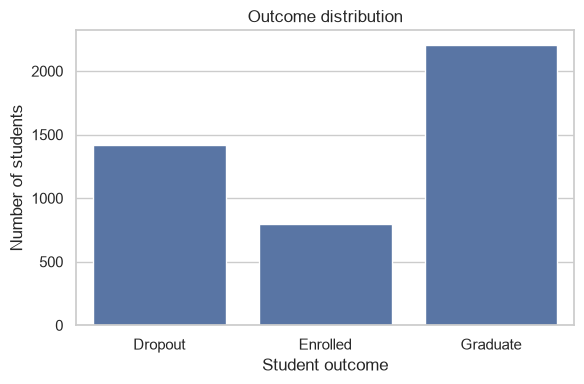

In [4]:
outcome_counts = student_records_table[OUTCOME_COLUMN_NAME].value_counts().reindex(OUTCOME_CLASS_NAMES)
outcome_share_percent = (outcome_counts / outcome_counts.sum() * 100).round(1)
print(pd.DataFrame({"students": outcome_counts, "share_percent": outcome_share_percent}).to_string())

figure, axis = plt.subplots(figsize=(6, 4))
sns.barplot(x=outcome_counts.index, y=outcome_counts.values, ax=axis)
axis.set_xlabel("Student outcome")
axis.set_ylabel("Number of students")
axis.set_title("Outcome distribution")
plt.tight_layout()
plt.show()

## 4. Which columns are really categories?

Many columns are stored as numbers but are actually category codes (for example *Course* or *Marital Status*). Counting the distinct values per column helps decide which ones need one-hot encoding and which are genuine numeric measurements.

In [5]:
distinct_values_per_feature = (
    student_records_table.drop(columns=[OUTCOME_COLUMN_NAME]).nunique().sort_values()
)
print(distinct_values_per_feature.to_string())

Daytime/evening attendance                          2
Displaced                                           2
Debtor                                              2
Educational special needs                           2
International                                       2
Scholarship holder                                  2
Gender                                              2
Tuition fees up to date                             2
Marital Status                                      6
Application order                                   8
Inflation rate                                      9
Curricular units 2nd sem (without evaluations)     10
GDP                                                10
Unemployment rate                                  10
Curricular units 1st sem (without evaluations)     11
Previous qualification                             17
Course                                             17
Application mode                                   18
Curricular units 2nd sem (cr

## 5. Academic grades by outcome

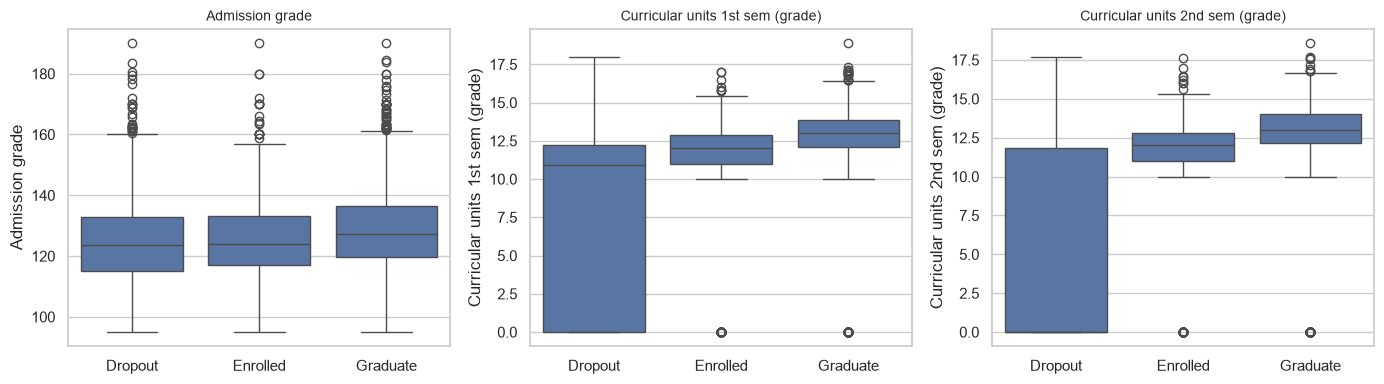

In [6]:
grade_columns_to_compare = [
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
]

figure, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, grade_column in zip(axes, grade_columns_to_compare):
    sns.boxplot(
        data=student_records_table,
        x=OUTCOME_COLUMN_NAME,
        y=grade_column,
        order=OUTCOME_CLASS_NAMES,
        ax=axis,
    )
    axis.set_title(grade_column, fontsize=10)
    axis.set_xlabel("")
plt.tight_layout()
plt.show()

## 6. Findings

- **Size:** 4,424 students and 36 input features, well above the assignment minimums of 500 rows and 12 features.
- **Quality:** no missing cells and no duplicated rows, so no imputation or row removal is needed.
- **Class balance:** Graduate 49.9%, Dropout 32.1%, Enrolled 17.9%. The classes are imbalanced, so plain accuracy can look good while the small Enrolled class is predicted badly. This is why macro-averaged precision, recall, F1 and AUC, together with MCC, are reported.
- **Feature types:** 29 columns are integers, 7 are decimals and the outcome is text. Many integer columns are category codes (Course has 17 values, Application mode 18, the parents' occupation and qualification columns 29 to 46). Treating these codes as plain numbers would imply a false order, so the nominal columns will be one-hot encoded and the genuine measurements will be scaled.
- **Signal in the grades:** the median second-semester grade is 0.0 for Dropout but 12.0 for Enrolled and 13.0 for Graduate. Median first-semester grades follow the same order (10.9, 12.0, 13.0). Early academic performance clearly separates the outcomes, so even simple models should do reasonably well.